# 06 · Careers, retention & the point of decline

Three questions:
1. **What's already known?** Public methods for predicting fights, and published work on careers and decline.
2. **Retention:** how long do UFC careers last, and what predicts a short one?
3. **Decline:** is there a point a fighter hits that signals the downfall, and can we see it coming in the data?

Reusable code lives in `src/ufc/careers.py`. Every number in the text below comes from the outputs of this notebook.

## 1 · What's out there

**Predicting winners**
| Approach | Typical honest accuracy | Notes |
|---|---|---|
| Betting odds (closing favorite) | **66–69%** | 68.6% over 6,210 fights; well calibrated. The real benchmark. ([UFCalendar 14-yr study](https://www.ufcalendar.com/blog/ufc-odds-line-movement-14-year-study), [AgentMMA](https://agentmma.com/mma-lab/ufc-favorites-win-rate)) |
| Rating systems (Elo / Bradley-Terry) | 55–60% alone | Elo is an online version of the Bradley-Terry model ([Király & Qian](https://arxiv.org/abs/1701.08055v1)) |
| ML on pre-fight stat differences | 60–70% | logistic regression, gradient boosting, small neural nets ([U of T](https://www.eecg.utoronto.ca/~jayar/ece324/2019/mmanet.pdf), [CMU](https://www.stat.cmu.edu/capstoneresearch/460files_s25/team11.pdf)) |
| "80%+" claims | — | almost always leakage: career stats from after the fight, or random train/test splits. Exactly the two traps from notebooks 01–04. |

Our notebook-04 model (64.3%) is in the honest range, a few points behind the betting market.

**Careers and decline**: mostly blog analyses, not peer-reviewed. That's why we check them against our data:
- debut winners average **8.3** UFC fights, debut losers **4.7**; a KO loss on debut drops it to **3.8** ([AgentMMA](https://agentmma.com/mma-lab/ufc-debut-loss-career-length))
- median fighter peaks at **30.6**, has their last fight at **34.6**, and wins **~31%** of their fights after the peak ([UFCalendar](https://www.ufcalendar.com/blog/when-do-ufc-fighters-get-washed))
- the **"9-year rule"**: decline starts around 9 years into a pro career ([Fight Opinion](https://www.fightopinion.com/2011/06/19/9-year-rule-mma-ufc/), [Bloody Elbow](https://bloodyelbow.com/2013/07/18/ufc-going-deeper-into-mma-fighter-longevity-does-age-matter))
- KO-loss rate rises in every age band; past 40 about **28%** of appearances end in a KO loss ([AgentMMA](https://agentmma.com/mma-lab/ufc-fighter-peak-age))
- prior KO losses are the strongest predictor of the next one ([AgentMMA](https://agentmma.com/mma-lab/ufc-knockout-loss-repeat-risk), [RAMA 2023](https://doaj.org/article/b12f3505b5494fe98e56eb45bba29a22))

**The gap:** every one of these compares *different* fighters at different ages. Fighters who decline early leave the sample, so the survivors make age look kinder than it is. Sections 4–5 measure decline **within each fighter** instead.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)

from ufc import careers as C
from ufc.viz import use_style, SERIES, INK_2, NEUTRAL, GRID, METHOD_COLORS
use_style()

ff = pd.read_parquet("data/processed/fighter_fights.parquet")
hist = pd.read_parquet("data/processed/elo_history.parquet")
fighters = pd.read_parquet("data/processed/fighters.parquet")

perf = C.per_fight_perf(ff, hist)
car = C.career_table(perf, fighters)
DATA_END = perf.date.max()
print(f"{len(car):,} fighters · {perf.fight_id.nunique():,} fights · {perf.date.min():%Y} → {DATA_END:%Y-%m-%d}")
print(f"careers over (no fight in 18 months): {car.retired.mean():.0%}")

2,777 fighters · 8,947 fights · 1994 → 2026-10-17
careers over (no fight in 18 months): 73%


Only *who won* matters for careers, so the pre-2010 red-corner quirk doesn't affect this notebook and every fight back to 1994 is used.
A career counts as **over** after 18 months without a UFC fight. That includes being cut or leaving for another promotion, so "career" means *UFC career*.

## 2 · Trends

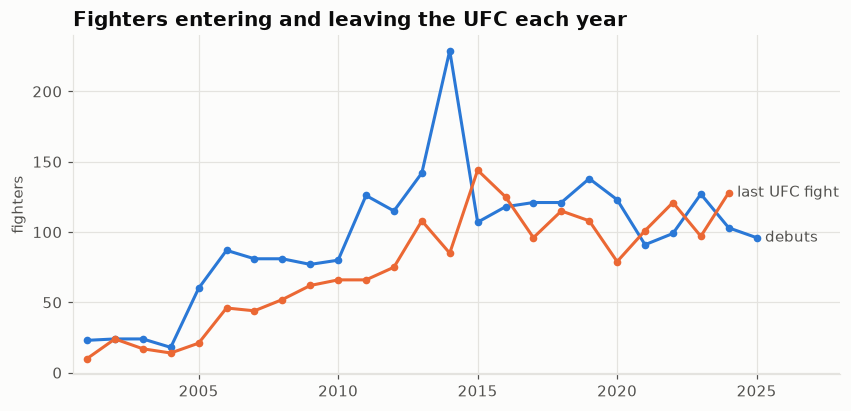

25 full years shown; exits stop at 2024 because a fighter only counts as gone after 18 months


In [2]:
cutoff = DATA_END - pd.Timedelta(days=C.RETIRED_AFTER_DAYS)
debuts = car.groupby(car.debut_date.dt.year).size()
exits = car[car.retired].groupby(car[car.retired].last_date.dt.year).size()
exits = exits[exits.index <= cutoff.year - 1]          # later years: exits not knowable yet
years = range(2001, DATA_END.year)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(debuts.reindex(years), color=SERIES[0], marker="o", ms=4)
ax.plot(exits.reindex(years), color=SERIES[1], marker="o", ms=4)
ax.text(years[-1] + 0.3, debuts.loc[years[-1]], "debuts", color=INK_2, va="center")
ax.text(exits.index[-1] + 0.3, exits.iloc[-1], "last UFC fight", color=INK_2, va="center")
ax.set_xlim(2000.5, years[-1] + 3)
ax.set_title("Fighters entering and leaving the UFC each year")
ax.set_ylabel("fighters")
plt.show()
print(f"{len(years)} full years shown; exits stop at {exits.index[-1]} because a fighter only counts as gone after 18 months")

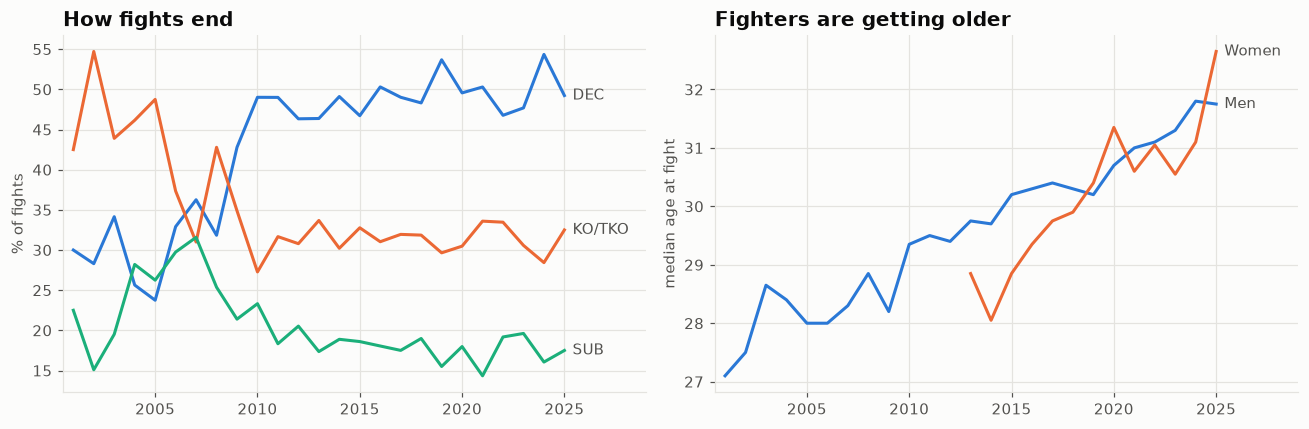

decision share 28% (2001-05) → 50% (last 5 yrs)
median age (men) 27.9 → 31.4


In [3]:
p = perf.drop_duplicates("fight_id")
share = pd.crosstab(p.date.dt.year, p.method_group, normalize="index").loc[2001:DATA_END.year - 1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
for m in ["DEC", "KO/TKO", "SUB"]:
    ax.plot(share.index, share[m] * 100, color=METHOD_COLORS[m])
    ax.text(share.index[-1] + 0.4, share[m].iloc[-1] * 100, m, color=INK_2, va="center")
ax.set_xlim(2000.5, share.index[-1] + 4); ax.set_ylabel("% of fights"); ax.set_title("How fights end")

ax = axes[1]
age = perf[perf.date.dt.year.between(2001, DATA_END.year - 1)]
med = age.groupby([age.date.dt.year, "gender"]).age.median().unstack()
for i, gsex in enumerate(["Men", "Women"]):
    s = med[gsex].dropna()
    ax.plot(s.index, s, color=SERIES[i]); ax.text(s.index[-1] + 0.4, s.iloc[-1], gsex, color=INK_2, va="center")
ax.set_xlim(2000.5, med.index[-1] + 4); ax.set_ylabel("median age at fight"); ax.set_title("Fighters are getting older")
plt.tight_layout(); plt.show()
print("decision share", f"{share.DEC.iloc[:5].mean():.0%} (2001-05) → {share.DEC.iloc[-5:].mean():.0%} (last 5 yrs)")
print("median age (men)", f"{med.Men.iloc[:5].mean():.1f} → {med.Men.iloc[-5:].mean():.1f}")

## 3 · Retention: survival analysis

How many UFC fights does a career last? The catch is **censoring**: about a quarter of fighters are still active, so we only know their career is *at least* this long.
Dropping them biases careers short, and treating them as finished does too.

The **Kaplan-Meier** estimator handles this. At each career length *t* it asks: *of the fighters still around at fight t, what share had their last fight here?*
Chaining those survival chances gives S(t) = P(career lasts longer than t fights). Active fighters count while they're observed, then drop out of the denominator.

We use fighters who debuted from 2001 (the modern era) on.

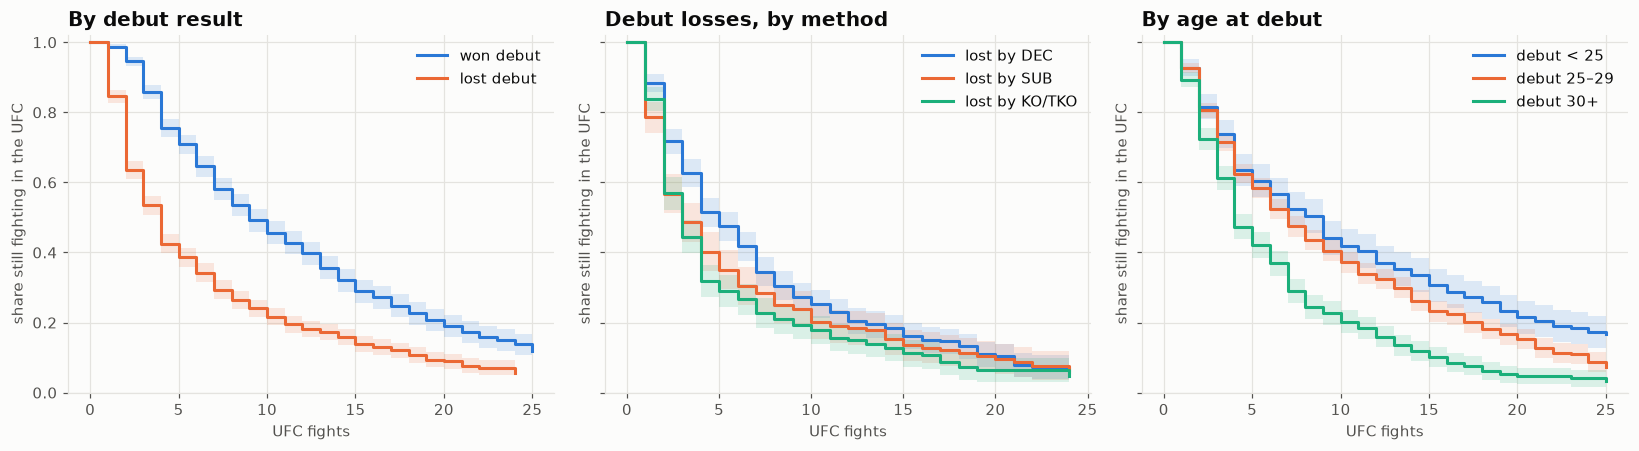

,group,fighters,still active,median fights,expected fights (cap 20)
0,won debut,1129,37%,9.0,10.7
1,lost debut,1369,23%,4.0,6.5
2,lost by DEC,596,26%,5.0,7.3
3,lost by SUB,317,20%,3.0,6.2
4,lost by KO/TKO,447,21%,3.0,5.6
5,debut < 25,454,29%,9.0,10.0
6,debut 25–29,1244,32%,7.0,9.1
7,debut 30+,795,24%,4.0,6.4


In [4]:
m = car[car.debut_date >= "2001-01-01"].copy()
# unit check: with no censoring, Kaplan-Meier equals the plain share of careers longer than t
d = m.n_fights.values
km_all = C.kaplan_meier(d, np.ones(len(d), bool))
assert np.allclose(km_all.surv, [(d > t).mean() for t in km_all.index])

def km_plot(ax, groups, title):
    rows = []
    for i, (label, grp) in enumerate(groups):
        km = C.kaplan_meier(grp.n_fights, grp.retired)
        km = km[km.index <= 25]
        ax.step(km.index, km.surv, where="post", color=SERIES[i], label=label)
        ax.fill_between(km.index, km.lo, km.hi, step="post", color=SERIES[i], alpha=0.15, lw=0)
        rows.append({"group": label, "fighters": len(grp), "still active": f"{(~grp.retired).mean():.0%}",
                     "median fights": C.km_median(km), "expected fights (cap 20)": round(C.km_restricted_mean(km, 20), 1)})
    ax.set_title(title); ax.set_xlabel("UFC fights"); ax.set_ylim(0, 1.02)
    ax.set_ylabel("share still fighting in the UFC"); ax.legend()
    return pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
t1 = km_plot(axes[0], [("won debut", m[m.debut_result == "W"]), ("lost debut", m[m.debut_result == "L"])], "By debut result")
lost = m[m.debut_result == "L"]
t2 = km_plot(axes[1], [(f"lost by {k}", lost[lost.debut_method == k]) for k in ["DEC", "SUB", "KO/TKO"]], "Debut losses, by method")
band = pd.cut(m.debut_age, [0, 25, 30, 99], right=False, labels=["debut < 25", "debut 25–29", "debut 30+"])
t3 = km_plot(axes[2], [(str(b), m[band == b]) for b in band.cat.categories], "By age at debut")
plt.tight_layout(); plt.show()
display(pd.concat([t1, t2, t3], ignore_index=True))

In [5]:
ret = m[m.retired]
check = pd.DataFrame({
    "published": [8.3, 4.7, 5.4, 3.8],
    "ours (finished careers)": [ret[ret.debut_result == "W"].n_fights.mean(), ret[ret.debut_result == "L"].n_fights.mean(),
                                ret[(ret.debut_result == "L") & (ret.debut_method == "DEC")].n_fights.mean(),
                                ret[(ret.debut_result == "L") & (ret.debut_method == "KO/TKO")].n_fights.mean()],
}, index=["won debut", "lost debut", "lost debut by decision", "lost debut by KO/TKO"]).round(1)
check

,published,ours (finished careers)
won debut,8.3,8.3
lost debut,4.7,4.4
lost debut by decision,5.4,5.0
lost debut by KO/TKO,3.8,3.7


**Reading this:**
- The debut matters a lot. Debut winners' median career is roughly **twice as long** as debut losers'. The published 8.3 vs 4.7 replicates closely.
- How you lose matters too. A KO/TKO debut loss gives the shortest careers. A submission loss is close behind, and a decision loss holds up best.
- Age at debut matters less than the debut result, but older debutants have shorter careers. They have less time left before the decline in section 4.
- Debut result isn't the *cause* of a long career. It's an early, noisy read on talent, and the UFC cuts quickly after losses.

## 4 · Aging curves: when does decline start?

### 4a · The cleanest signal: results vs Elo expectation
Elo already tracks each fighter's current level (notebook 05). So **result minus Elo-expected win chance** asks whether fighters at this age do better or worse than their *own* rating says.
- **Positive:** they're improving faster than the rating keeps up.
- **Negative:** the rating overstates them, so they're declining.

This compares each fighter with themselves, which avoids the survivor problem. ×64 (the Elo K) converts it to Elo points per fight.

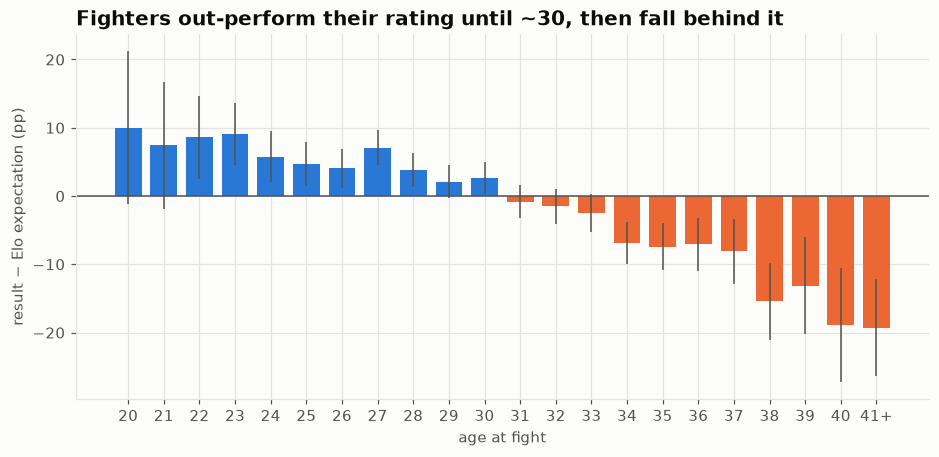

first age with a negative average: 31


age,20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,36.0,37.0,38.0,39.0,40.0,41.0
mean,0.100,0.074,0.086,0.091,0.058,0.046,0.041,0.070,0.038,0.021,0.027,-0.008,-0.015,-0.024,-0.069,-0.074,-0.071,-0.081,-0.154,-0.131,-0.189,-0.193
lo,-0.012,-0.019,0.025,0.046,0.020,0.014,0.012,0.045,0.014,-0.003,0.003,-0.032,-0.041,-0.052,-0.100,-0.109,-0.110,-0.129,-0.210,-0.202,-0.272,-0.264
hi,0.212,0.168,0.147,0.136,0.095,0.078,0.069,0.096,0.063,0.045,0.051,0.016,0.011,0.004,-0.039,-0.040,-0.032,-0.034,-0.098,-0.061,-0.105,-0.122
size,69.000,109.000,246.000,446.000,648.000,918.000,1158.000,1413.000,1564.000,1638.000,1659.000,1601.000,1398.000,1182.000,1015.000,779.000,601.000,425.000,283.000,178.000,122.000,167.000
elo_pts_per_fight,6.421,4.744,5.497,5.805,3.694,2.975,2.597,4.511,2.451,1.344,1.719,-0.532,-0.960,-1.560,-4.421,-4.767,-4.536,-5.193,-9.859,-8.397,-12.089,-12.365


In [6]:
fa = C.form_by(perf, "age", lo=20, hi=41)
fig, ax = plt.subplots(figsize=(10, 4.3))
colors = [SERIES[0] if v >= 0 else SERIES[1] for v in fa["mean"]]
ax.bar(fa.index, fa["mean"] * 100, color=colors, width=0.75)
ax.errorbar(fa.index, fa["mean"] * 100, yerr=1.96 * fa["sem"] * 100, fmt="none", ecolor=INK_2, lw=1, capsize=0)
ax.axhline(0, color=INK_2, lw=1)
ax.set_xticks(fa.index, [f"{int(a)}" if a < 41 else "41+" for a in fa.index])
ax.set_xlabel("age at fight"); ax.set_ylabel("result − Elo expectation (pp)")
ax.set_title("Fighters out-perform their rating until ~30, then fall behind it")
plt.show()
cross = fa.index[(fa["mean"] < 0)][0]
print(f"first age with a negative average: {cross:.0f}")
display((fa.assign(elo_pts_per_fight=fa["mean"] * 64)[["mean", "lo", "hi", "size", "elo_pts_per_fight"]]).round(3).T)

**The answer to "is there a point?"** Yes, and it's around **31**. That's the first age where the average turns negative.
At 31–33 the shortfall is small (the interval still touches zero). From **34** it's clearly negative, and it roughly doubles again at **38+**.
In Elo terms, a 35-year-old's rating is about 5 points per fight too high, and a 40-year-old's about 12.

The same view on the *career clock* (below) tests the "9-year rule". In UFC years, the turn comes around **year 5–6 after the UFC debut**, or **around fight 10–12**.
Most fighters have several pro fights before the UFC, so this is consistent with ~9 years as a pro.

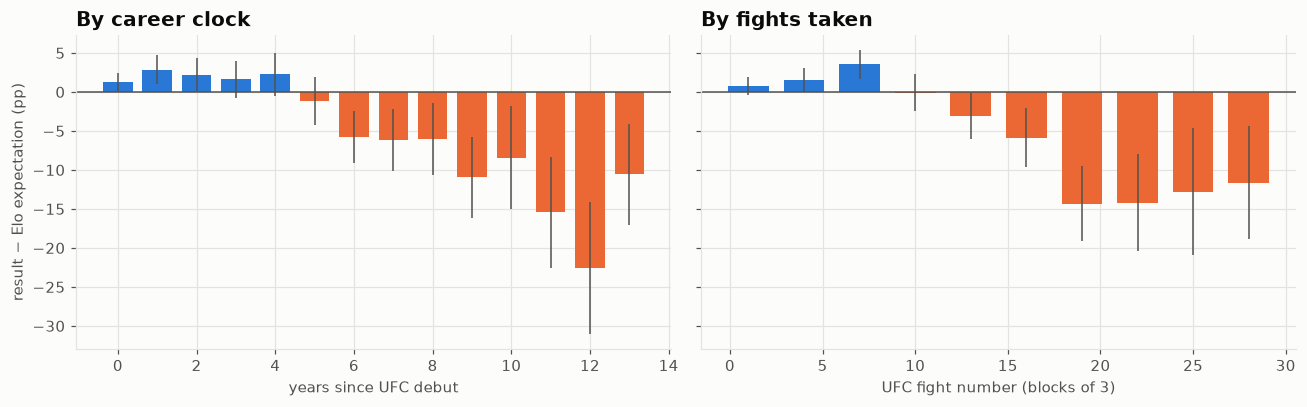

first negative year since debut: 5.0 · first negative fight block starts at fight 10


In [7]:
fy = C.form_by(perf, "years_active", hi=13)
fn = C.form_by(perf, "fight_no", hi=9)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, f, lab in [(axes[0], fy, "years since UFC debut"), (axes[1], fn, "UFC fight number (blocks of 3)")]:
    ax.bar(f.index, f["mean"] * 100, color=[SERIES[0] if v >= 0 else SERIES[1] for v in f["mean"]],
           width=0.75 if lab.startswith("years") else 2.2)
    ax.errorbar(f.index, f["mean"] * 100, yerr=1.96 * f["sem"] * 100, fmt="none", ecolor=INK_2, lw=1)
    ax.axhline(0, color=INK_2, lw=1); ax.set_xlabel(lab)
axes[0].set_ylabel("result − Elo expectation (pp)")
axes[0].set_title("By career clock"); axes[1].set_title("By fights taken")
plt.tight_layout(); plt.show()
print("first negative year since debut:", fy.index[fy["mean"] < 0][0], "· first negative fight block starts at fight", fn.index[fn["mean"] < 0][0])

### 4b · Which skills fade first? The delta method
For the raw stats (strike differential, damage absorbed, defense) we use the **delta method** from baseball aging research.
1. For each fighter who fought at ages *a* and *a+1*, take the change in *their own* numbers.
2. Average those changes and chain them into a curve.

**Its trap, and the fix:** fighters who had a *lucky* year are the ones who get another year, so the raw changes are biased downward (regression to the mean).
We first shrink each fighter's year toward the average by its year-to-year reliability. The chart shows the uncorrected version so you can see how big the trap is.

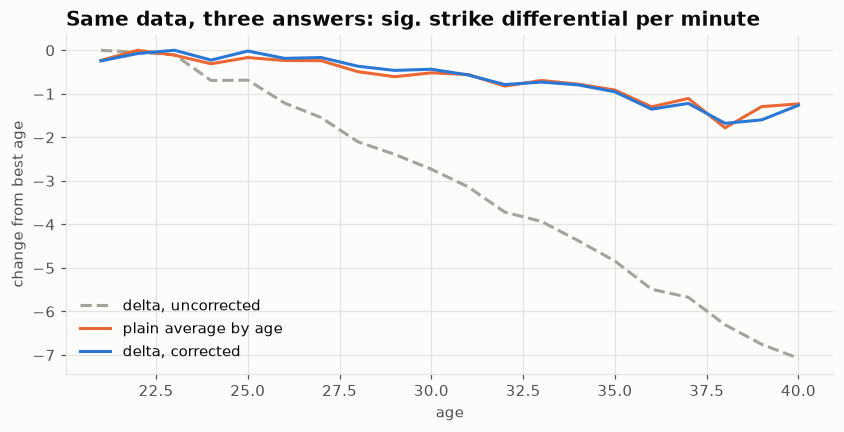

In [8]:
raw = C.aging_curve(perf, "sig_diff_pm", "age", shrink=False, n_boot=0, hi=40)
fix = C.aging_curve(perf, "sig_diff_pm", "age", shrink=True, n_boot=0, hi=40)
fig, ax = plt.subplots(figsize=(9, 4))
for s, lab, c, ls in [(raw.curve, "delta, uncorrected", NEUTRAL, "--"), (fix.naive, "plain average by age", SERIES[1], "-"),
                      (fix.curve, "delta, corrected", SERIES[0], "-")]:
    ax.plot(s.index, s, color=c, ls=ls, label=lab)
ax.legend(loc="lower left"); ax.set_xlabel("age"); ax.set_ylabel("change from best age")
ax.set_title("Same data, three answers: sig. strike differential per minute")
plt.show()

The uncorrected delta curve "declines" from age 21. That's pure selection: a fighter's good year buys them the next one.
After the correction, the within-fighter curve sits close to the plain average. Survivor bias in the plain average turns out to be modest for this metric, and the corrected curve is the one we trust.

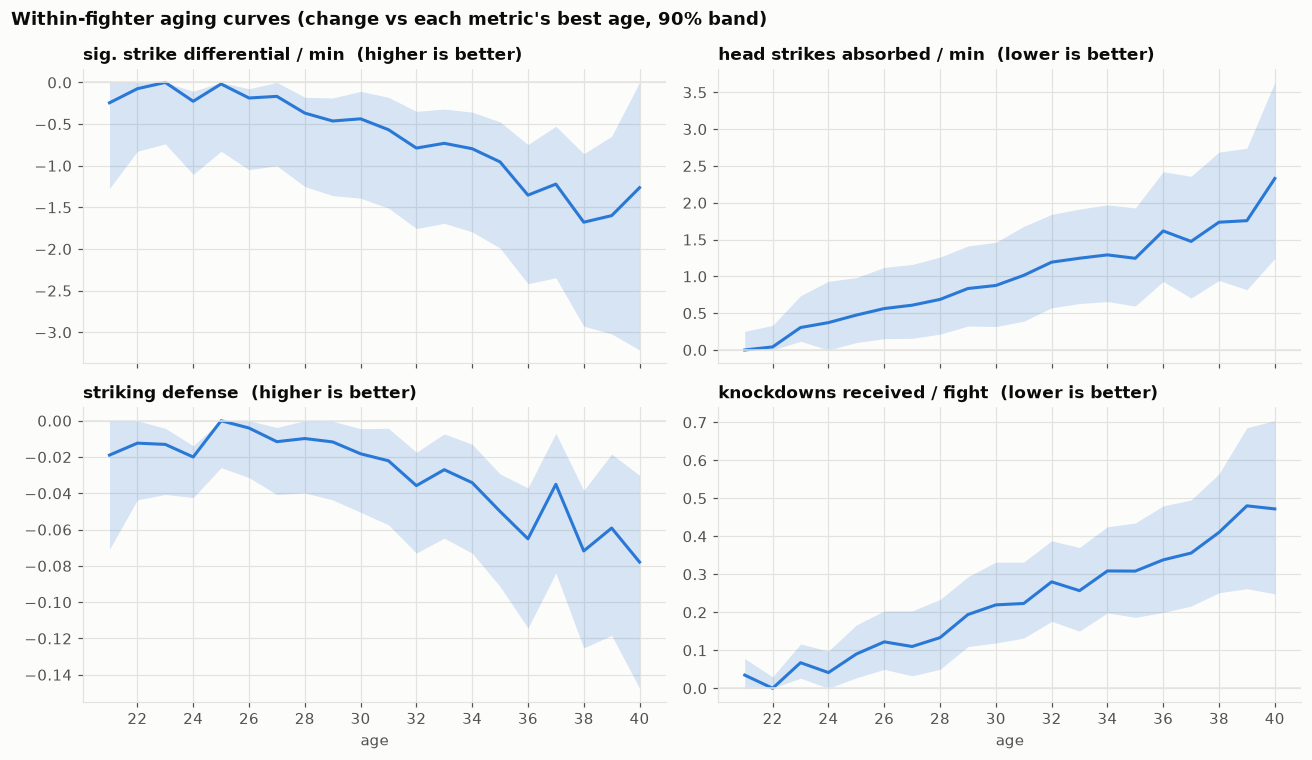

,best age,change by 35,change by 38
sig. strike differential / min,23.0,-0.954,-1.678
head strikes absorbed / min,21.0,1.245,1.736
striking defense,25.0,-0.050,-0.072
knockdowns received / fight,22.0,0.308,0.410


In [9]:
panel = ["sig_diff_pm", "head_abs_pm", "str_def", "kd_received"]
curves = {mt: C.aging_curve(perf, mt, "age", n_boot=200, hi=40) for mt in panel}
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, mt in zip(axes.flat, panel):
    a = curves[mt]; label, higher = C.METRICS[mt]
    ax.fill_between(a.index, a.lo, a.hi, color=SERIES[0], alpha=0.18, lw=0)
    ax.plot(a.index, a.curve, color=SERIES[0])
    ax.axhline(0, color=GRID, lw=1)
    ax.set_title(f"{label}  ({'higher' if higher else 'lower'} is better)", fontsize=11)
    ax.set_xticks(range(22, 41, 2))
for ax in axes[1]: ax.set_xlabel("age")
fig.suptitle("Within-fighter aging curves (change vs each metric's best age, 90% band)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

summary = pd.DataFrame({C.METRICS[mt][0]: {"best age": (curves[mt].curve.idxmax() if C.METRICS[mt][1] else curves[mt].curve.idxmin()),
                                           "change by 35": curves[mt].curve.loc[35], "change by 38": curves[mt].curve.loc[38]}
                        for mt in panel}).T.round(3)
summary

**Caveat:** strike stats also depend on opponents. A fighter who keeps winning faces better opponents, and their differential drops even without aging.
That's why 4a (opponent-adjusted through Elo) is the headline, and 4b shows *which parts* of the game go.

### 4c · Knockouts: age and accumulated damage

age_band,<25,25–27,28–30,31–33,34–36,37–39,40+
fights,1518.000,3489.000,4861.000,4181.000,2395.000,886.000,289.000
win_rate,0.577,0.555,0.526,0.484,0.428,0.397,0.336
ko_loss_rate,0.115,0.126,0.150,0.172,0.215,0.238,0.284


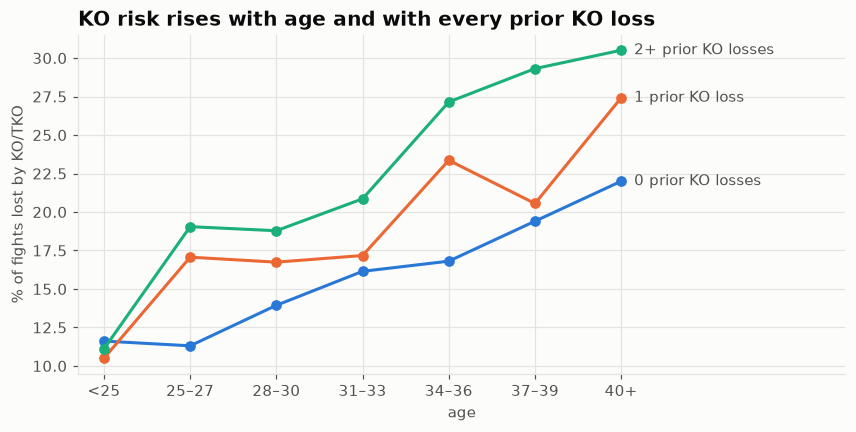

,0 prior KO losses,1 prior KO loss,2+ prior KO losses
age_band,,,
<25,0.116,0.105,0.111
25–27,0.113,0.171,0.190
28–30,0.139,0.167,0.188
31–33,0.161,0.172,0.209
34–36,0.168,0.234,0.271
37–39,0.194,0.206,0.293
40+,0.220,0.274,0.305


In [10]:
p = perf[perf.age.notna()].copy()
p["age_band"] = pd.cut(p.age, [0, 25, 28, 31, 34, 37, 40, 60], right=False,
                       labels=["<25", "25–27", "28–30", "31–33", "34–36", "37–39", "40+"])
p["prior_ko"] = (p.groupby("fighter").ko_loss.cumsum() - p.ko_loss).clip(upper=2)
by_age = p.groupby("age_band", observed=True).agg(fights=("ko_loss", "size"), win_rate=("win", "mean"), ko_loss_rate=("ko_loss", "mean"))
display(by_age.round(3).T)
grid = p.pivot_table(index="age_band", columns="prior_ko", values="ko_loss", aggfunc="mean", observed=True)
grid.columns = ["0 prior KO losses", "1 prior KO loss", "2+ prior KO losses"]
fig, ax = plt.subplots(figsize=(9, 4))
for i, col in enumerate(grid.columns):
    ax.plot(range(len(grid)), grid[col] * 100, color=SERIES[i], marker="o")
    ax.text(len(grid) - 1 + 0.15, grid[col].iloc[-1] * 100, col, color=INK_2, va="center")
ax.set_xticks(range(len(grid)), grid.index); ax.set_xlim(-0.3, len(grid) + 1.6)
ax.set_xlabel("age"); ax.set_ylabel("% of fights lost by KO/TKO")
ax.set_title("KO risk rises with age and with every prior KO loss")
plt.show()
grid.round(3)

Both effects stack. A 34–36-year-old with 2+ prior KO losses is knocked out far more often than a young fighter with none.
This compares *different* fighters, so it can't separate a fighter "losing their chin" from "some fighters are just more hittable".
Either way, for predicting what happens *next* the pattern is real.

## 5 · The point of no return

### 5a · When do careers peak?
For finished careers with at least 8 UFC fights, the **peak** is the fight that produced the fighter's highest Elo.
By definition, the rating never gets back there afterwards.

,published,ours
median peak age,30.600,31.200
median age at last fight,34.600,34.500
years from peak to last fight,3.400,2.900
win rate after peak,0.308,0.247


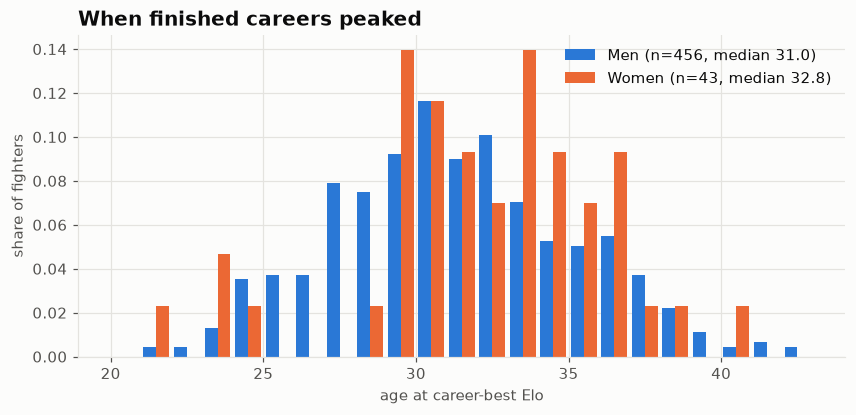

weight_class,Featherweight,Lightweight,Welterweight,Flyweight,Bantamweight,Middleweight,Light Heavyweight,Heavyweight
median,29.4,30.4,30.5,30.6,30.7,31.8,31.9,32.9
size,43.0,88.0,88.0,16.0,45.0,72.0,47.0,49.0


In [11]:
vet = car[car.retired & (car.n_fights >= 8) & car.peak_age.notna()].copy()
vet["peak_to_last"] = vet.last_age - vet.peak_age
bench = pd.DataFrame({
    "published": [30.6, 34.6, 3.4, 0.308],
    "ours": [vet.peak_age.median(), vet.last_age.median(), vet.peak_to_last.median(),
             (vet.win_rate_after_peak * vet.fights_after_peak).sum() / vet.fights_after_peak.sum()],
}, index=["median peak age", "median age at last fight", "years from peak to last fight", "win rate after peak"]).round(3)
display(bench)

fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.arange(20, 44)
data = [vet[vet.gender == g].peak_age for g in ["Men", "Women"]]
ax.hist(data, bins=bins, color=SERIES[:2], density=True, rwidth=0.85,
        label=[f"{g} (n={len(s)}, median {s.median():.1f})" for g, s in zip(["Men", "Women"], data)])
ax.set_xlabel("age at career-best Elo"); ax.set_ylabel("share of fighters"); ax.legend()
ax.set_title("When finished careers peaked")
plt.show()
div = vet[vet.gender == "Men"].groupby("weight_class").peak_age.agg(["median", "size"])
div[div["size"] >= 15].sort_values("median").round(1).T

Our "win rate after the peak" is lower than the published ~31% because of how the peak is defined. Our peak is the fighter's *highest rating*, so it lands right before the losses start.
The published rating peaks a bit earlier.

### 5b · What changes at the peak? An event study
Line up every veteran's career on their peak fight (t = 0) and average each signal at t = −5 … +5.
If there's a "global indicator", it should **move before or right at** the turn, not only after.

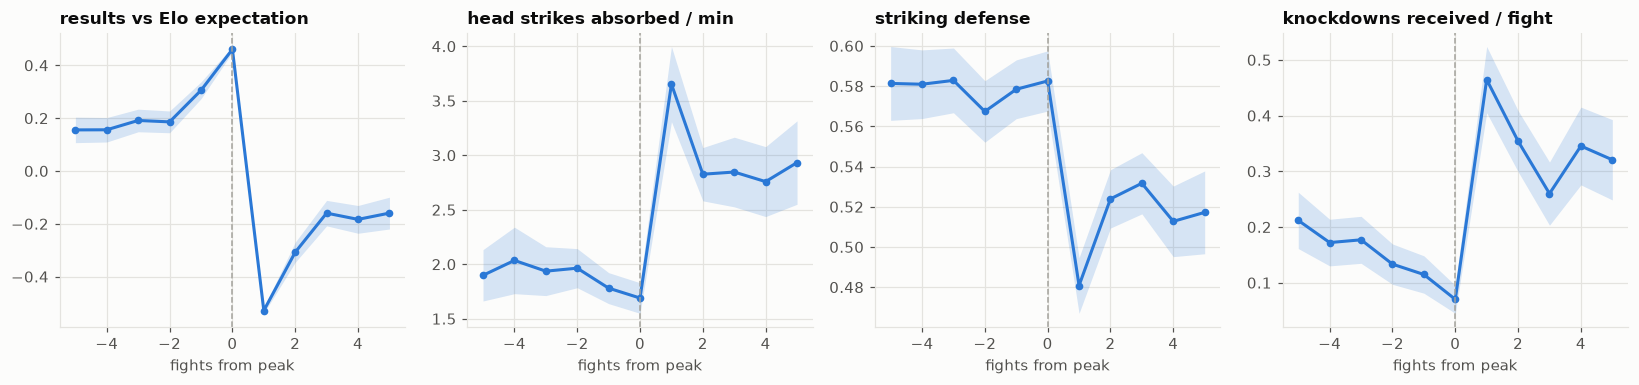

t,-5,-4,-3,-2,-1,0,1,2,3,4,5
elo_surprise,0.156,0.156,0.191,0.186,0.305,0.461,-0.528,-0.308,-0.160,-0.183,-0.159
head_abs_pm,1.898,2.035,1.936,1.964,1.781,1.690,3.653,2.826,2.846,2.758,2.933
str_def,0.581,0.581,0.583,0.567,0.578,0.583,0.481,0.524,0.532,0.513,0.517
kd_received,0.212,0.172,0.177,0.133,0.115,0.070,0.465,0.354,0.260,0.345,0.321


In [12]:
ev = perf.merge(vet[["peak_fight_no"]], left_on="fighter", right_index=True)
ev["t"] = ev.fight_no - ev.peak_fight_no
ev = ev[ev.t.between(-5, 5)]
sig = ["elo_surprise", "head_abs_pm", "str_def", "kd_received"]
es = ev.groupby("t")[sig].agg(["mean", "sem"])
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharex=True)
for ax, s in zip(axes, sig):
    mu, se = es[(s, "mean")], es[(s, "sem")]
    ax.fill_between(mu.index, mu - 1.96 * se, mu + 1.96 * se, color=SERIES[0], alpha=0.18, lw=0)
    ax.plot(mu.index, mu, color=SERIES[0], marker="o", ms=4)
    ax.axvline(0, color=NEUTRAL, lw=1, ls="--")
    ax.set_title(C.METRICS[s][0], fontsize=11); ax.set_xlabel("fights from peak")
plt.tight_layout(); plt.show()
es.xs("mean", axis=1, level=1).round(3).T

**Careful reading:** the peak is defined by results, so the fights just before it are wins and the fight after it is usually a loss. The spike at t = +1 is partly built in.
The useful parts are the two sides of the chart:
- **Before the peak there's no warning drift.** Damage absorbed and knockdowns actually *improve* into the peak. The top of a career looks like the best version of the fighter, not like a fighter about to fall.
- **After the peak, the damage profile settles at a worse level.** Head strikes absorbed per minute and knockdowns received stay well above pre-peak levels for the next five fights, and defense stays lower. The first loss isn't a blip; it's a new baseline.

So the "point" is only visible in hindsight from the fight itself. To see it *coming* we need slower signals: age, career length, and where the rating sits relative to its best.

### 5c · Can we see it coming? An early-warning model
For every fight by a veteran (5+ prior UFC fights), the target is **"loses at least 2 of this fight and the next 2"**, or the career ends on a loss first.
Features use only what's known before the fight. This is checked by brute force below.

| feature | meaning |
|---|---|
| `age`, `years_active`, `prior_fights` | the career clock |
| `elo_pre`, `opp_elo_pre` | current level, and this opponent's |
| `below_peak` | Elo points below the fighter's own best so far |
| `prior_ko_losses`, `ko_loss_last2` | durability |
| `head_abs_cum`, `head_abs_pm_last3` | total damage absorbed, and the recent rate |
| `sig_diff_trend`, `str_def_trend` | last 3 fights minus career average |
| `loss_streak`, `days_since_last` | momentum and layoff |

Train on windows that closed before 2020; test on fights from 2020 on.

In [13]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from ufc.features import Clipper

w = C.warning_table(perf, car)
assert C.check_warning_no_lookahead(perf, w)
train, test = w[w.label_date < "2020-01-01"], w[w.date >= "2020-01-01"]
y_tr, y_te = train.bad_stretch.astype(int), test.bad_stretch.astype(int)
print(f"{len(train):,} train · {len(test):,} test rows · bad-stretch rate {y_tr.mean():.0%} / {y_te.mean():.0%}")

def model():
    return make_pipeline(Clipper(), SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000))

sets = {
    "base rate": None,
    "age only": ["age"],
    "career clock": ["age", "years_active", "prior_fights"],
    "clock + level (Elo)": ["age", "years_active", "prior_fights", "elo_pre", "opp_elo_pre", "below_peak"],
    "all features": C.WARN_FEATURES,
}
res, preds = {}, {}
for name, cols in sets.items():
    if cols is None:
        p = np.full(len(test), y_tr.mean())
    else:
        mdl = model().fit(train[cols], y_tr); p = mdl.predict_proba(test[cols])[:, 1]
    preds[name] = p
    res[name] = {"AUC": roc_auc_score(y_te, p) if np.std(p) else 0.5, "log loss": log_loss(y_te, p), "Brier": brier_score_loss(y_te, p)}
pd.DataFrame(res).T.round(3)

3,723 train · 2,956 test rows · bad-stretch rate 50% / 53%


,AUC,log loss,Brier
base rate,0.500,0.693,0.250
age only,0.615,0.671,0.239
career clock,0.612,0.673,0.240
clock + level (Elo),0.643,0.665,0.235
all features,0.642,0.674,0.239


The **clock + level** model wins: best AUC, log loss and Brier. Adding durability, damage and trend features doesn't improve it on 2020+ fights.
They carry the same information as age and rating. So the final early-warning model uses just six inputs: age, years active, UFC fights, own Elo, opponent's Elo, and points below own peak.
The coefficient chart still uses all features, to show how each one leans.

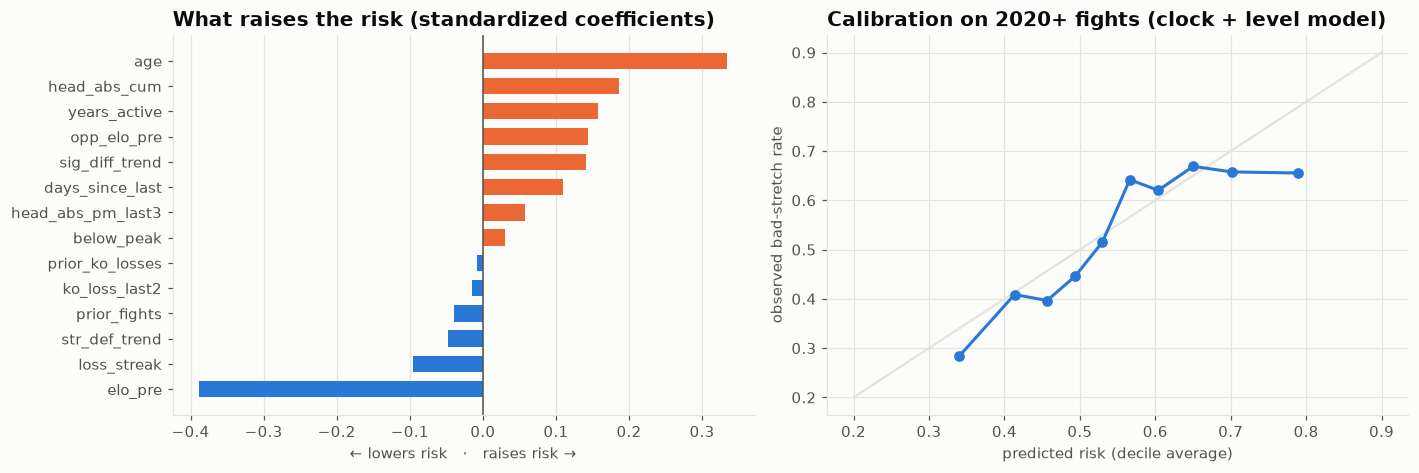

top-decile risk: 66% had a bad stretch vs 28% in the bottom decile
top-10% risk cutoff on the test period: 0.73


In [14]:
FINAL = sets["clock + level (Elo)"]
full = model().fit(train[C.WARN_FEATURES], y_tr)
coef = pd.Series(full[-1].coef_[0], C.WARN_FEATURES).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
ax.barh(coef.index, coef, color=[SERIES[1] if v > 0 else SERIES[0] for v in coef], height=0.65)
ax.axvline(0, color=INK_2, lw=1); ax.grid(axis="y", visible=False)
ax.set_title("What raises the risk (standardized coefficients)"); ax.set_xlabel("← lowers risk   ·   raises risk →")

ax = axes[1]
p = preds["clock + level (Elo)"]
q = pd.qcut(p, 10, labels=False, duplicates="drop")
cal = pd.DataFrame({"pred": p, "obs": y_te.values}).groupby(q).mean()
ax.plot([0.2, 0.9], [0.2, 0.9], color=GRID, lw=1.5)
ax.plot(cal.pred, cal.obs, color=SERIES[0], marker="o")
ax.set_xlabel("predicted risk (decile average)"); ax.set_ylabel("observed bad-stretch rate")
ax.set_title("Calibration on 2020+ fights (clock + level model)")
plt.tight_layout(); plt.show()
print(f"top-decile risk: {cal.obs.iloc[-1]:.0%} had a bad stretch vs {cal.obs.iloc[0]:.0%} in the bottom decile")
print(f"top-10% risk cutoff on the test period: {np.quantile(p, 0.9):.2f}")

**Reading this:**
- **Age is the single strongest push toward a bad stretch, and a high current rating is the strongest protection.** Everything else is a small adjustment on top.
- Read the coefficients **together**, because the features overlap. Accumulated head strikes and years active also lean toward risk. Loss streak and recent KO losses look "protective" only because Elo, held fixed, has already priced them in.
- **No single stat flips a switch.** The best model ranks risk moderately well (AUC ~0.64), and the top tenth of fighters by predicted risk have about twice the bad-stretch rate of the bottom tenth.
  Three fights is a small, noisy window, and matchmaking (who you face next) is out of the fighter's hands.
- Calibration: points near the diagonal mean "60% risk" really means about 60%. The highest-risk decile is a little overconfident.

### 5d · Rules of thumb
The same target, split by two simple, interpretable signals: age, and how far a fighter's rating has already fallen from their own peak.

In [15]:
t = w.copy()
t["age_band"] = pd.cut(t.age, [0, 30, 33, 36, 60], right=False, labels=["<30", "30–32", "33–35", "36+"])
t["below"] = pd.cut(t.below_peak, [-1, 0.5, 50, 100, 1e9], labels=["at peak", "1–50 below", "51–100 below", "100+ below"])
rule = t.pivot_table(index="age_band", columns="below", values="bad_stretch", aggfunc="mean", observed=True)
n = t.pivot_table(index="age_band", columns="below", values="bad_stretch", aggfunc="size", observed=True)
display(rule.style.format("{:.0%}").background_gradient(cmap="Oranges", vmin=0.3, vmax=0.8)
        .set_caption("Share of veterans who lose ≥2 of their next 3"))
n

below,at peak,1–50 below,51–100 below,100+ below
age_band,,,,
<30,38%,39%,42%,42%
30–32,43%,51%,49%,63%
33–35,52%,58%,65%,68%
36+,60%,66%,68%,67%


below,at peak,1–50 below,51–100 below,100+ below
age_band,,,,
<30,889,800,382,67
30–32,744,812,472,119
33–35,471,607,411,160
36+,257,365,334,269


## 6 · The greats
For each fighter:
- **Elo after every UFC fight**, with the rating peak marked.
- A **two-phase fit**: the best "rise, then fall" line through the rating. It's a brute-force search over every possible turning point.
- The **early-warning risk** before each fight. The model is re-fit *without that fighter*, so they aren't scoring themselves.

**Change the list to look at anyone.**

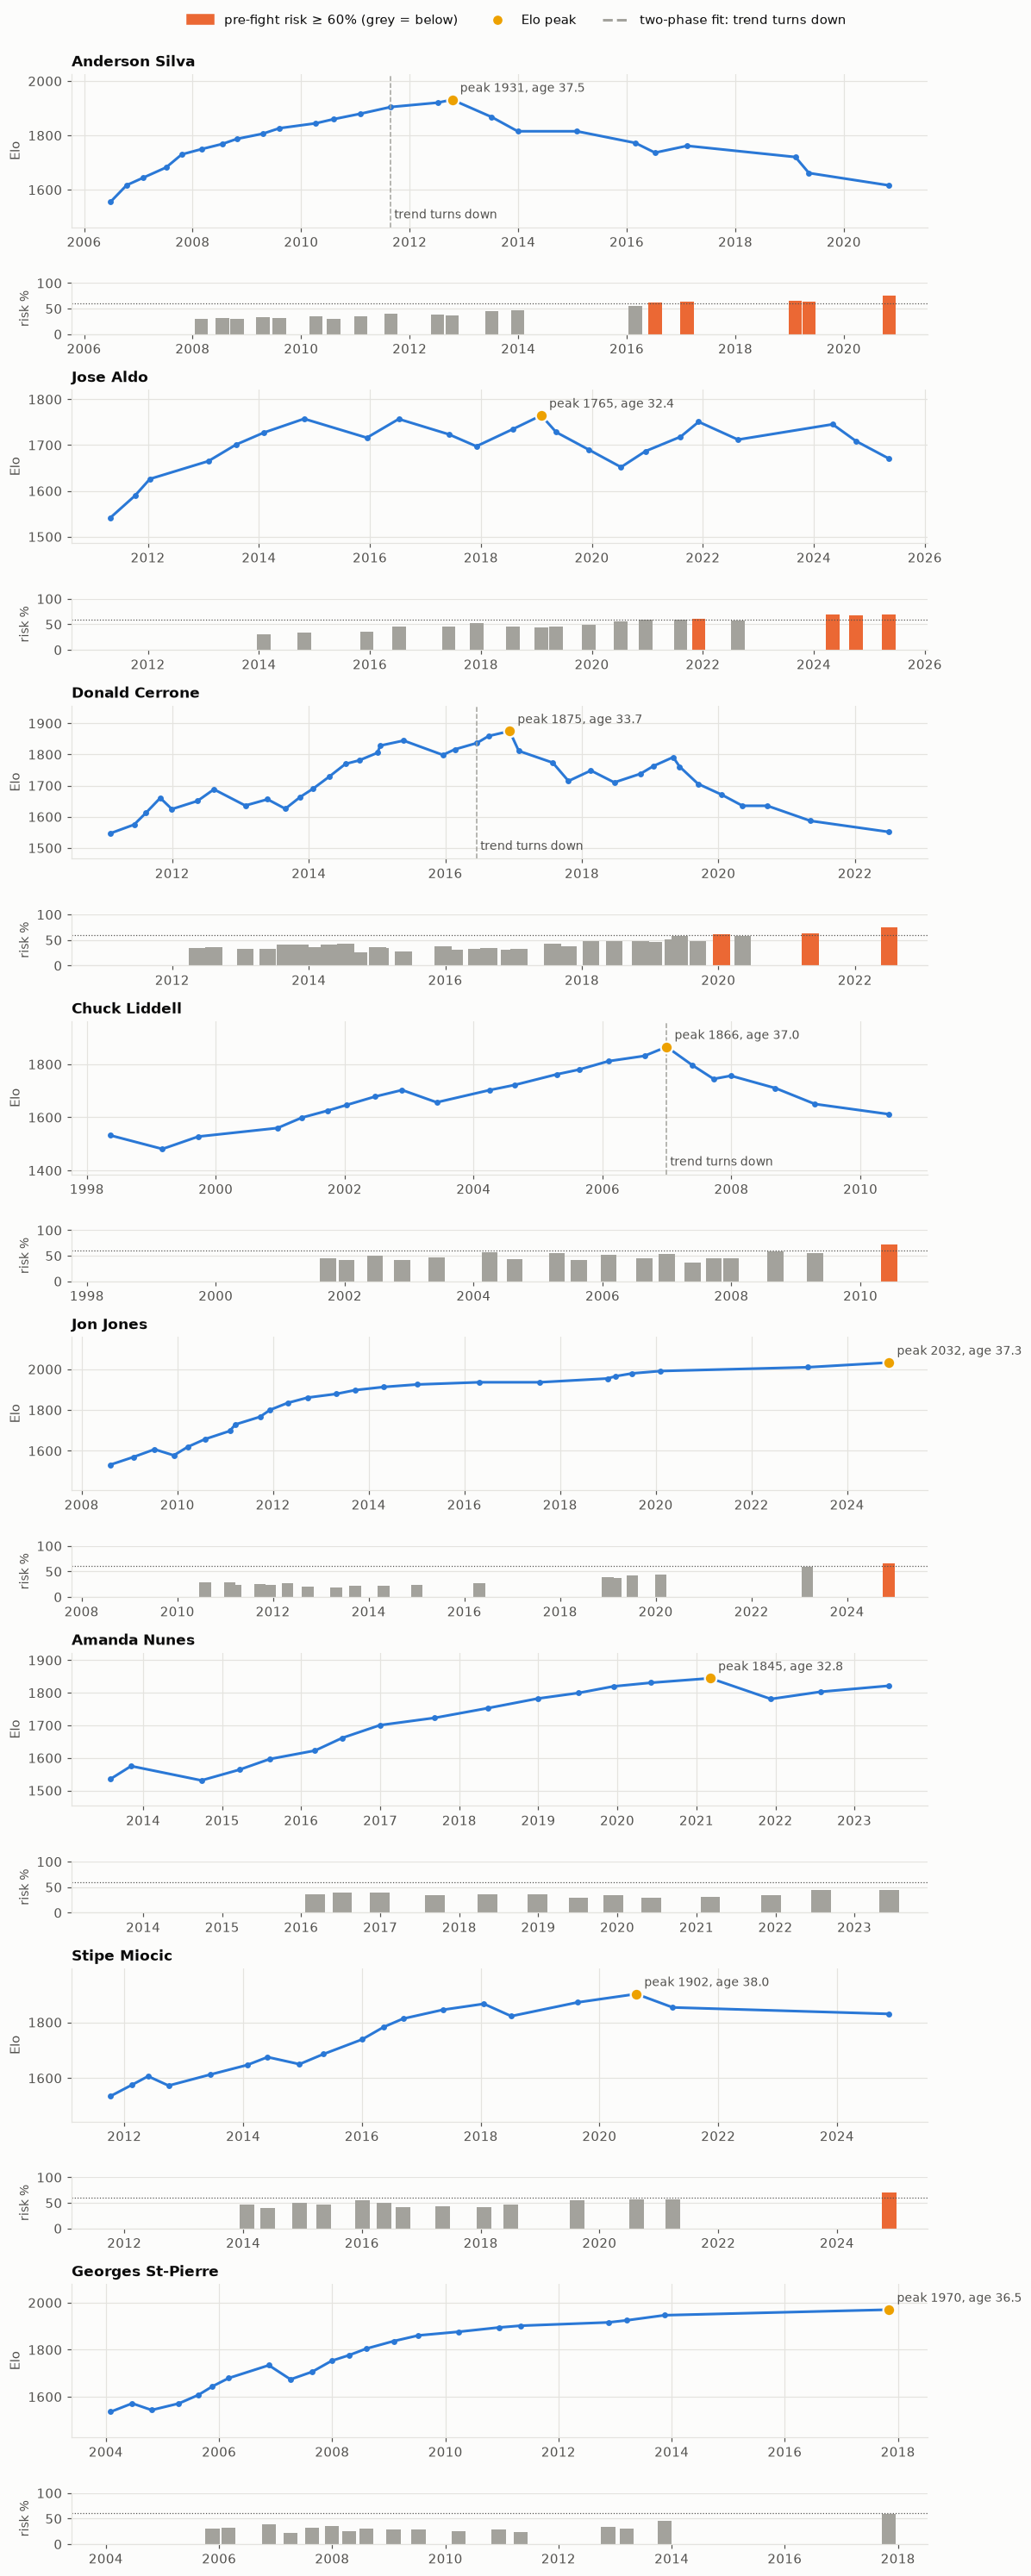

,UFC fights,peak date,peak age,trend turns down,first risk flag,age at flag,record after peak,last UFC fight
fighter,,,,,,,,
Anderson Silva,25,2012-10-13,37.5,2011-08-27,2016-07-09,41.2,1-7,2020-10-31
Jose Aldo,23,2019-02-02,32.4,—,2021-12-04,35.2,4-6,2025-05-10
Donald Cerrone,38,2016-12-10,33.7,2016-06-18,2020-01-18,36.8,4-10,2022-07-02
Chuck Liddell,23,2006-12-30,37.0,2006-12-30,2010-06-12,40.5,1-5,2010-06-12
Jon Jones,24,2024-11-16,37.3,—,2024-11-16,37.3,0-0,2024-11-16
Amanda Nunes,18,2021-03-06,32.8,—,—,NaN,2-1,2023-06-10
Stipe Miocic,19,2020-08-15,38.0,—,2024-11-16,42.2,0-2,2024-11-16
Georges St-Pierre,22,2017-11-04,36.5,—,—,NaN,0-0,2017-11-04


In [16]:
GREATS = ["Anderson Silva", "Jose Aldo", "Donald Cerrone", "Chuck Liddell",
          "Jon Jones", "Amanda Nunes", "Stipe Miocic", "Georges St-Pierre"]

RISK_FLAG = 0.60      # "more likely than not to lose 2 of the next 3, with some margin"

w_all = C.warning_table(perf, car, labeled_only=False)
rows = []
fig, axs = plt.subplots(2 * len(GREATS), 1, figsize=(11, 3.4 * len(GREATS)),
                        gridspec_kw={"height_ratios": [3, 1] * len(GREATS)})
for j, name in enumerate(GREATS):
    ax, rax = axs[2 * j], axs[2 * j + 1]
    f = perf[perf.fighter == name]
    fit = C.two_phase_fit(f.years_active.values, f.elo_post.values)
    others = w[w.fighter != name]
    mdl = model().fit(others[FINAL], others.bad_stretch.astype(int))
    fw = w_all[w_all.fighter == name]
    risk = pd.Series(mdl.predict_proba(fw[FINAL])[:, 1], index=fw.fight_no)

    ax.plot(f.date, f.elo_post, color=SERIES[0], marker="o", ms=3.5)
    pk = f.loc[f.elo_post.idxmax()]
    ax.scatter([pk.date], [pk.elo_post], s=80, color=SERIES[3], zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
    ax.annotate(f"peak {pk.elo_post:.0f}, age {pk.age:.1f}", (pk.date, pk.elo_post), xytext=(6, 6),
                textcoords="offset points", fontsize=9, color=INK_2)
    ax.margins(y=0.25)
    # a "turn" only counts if the rating really fell afterwards (>= 75 points along the fitted line)
    turn = None
    if fit and fit["slope_before"] > 0 and fit["slope_after"] * (f.years_active.max() - fit["k"]) <= -75:
        turn = f.debut_date.iloc[0] + pd.Timedelta(days=fit["k"] * 365.25)
        ax.axvline(turn, color=NEUTRAL, ls="--", lw=1)
        ax.text(turn, 0.04, " trend turns down", transform=ax.get_xaxis_transform(), color=INK_2, fontsize=9, va="bottom")
    flagged = risk[risk >= RISK_FLAG]
    fd = f.set_index("fight_no")
    rd = fd.loc[risk.index].date
    rax.bar(rd, risk.values * 100, width=90, color=[SERIES[1] if v >= RISK_FLAG else NEUTRAL for v in risk.values])
    rax.axhline(RISK_FLAG * 100, color=INK_2, lw=0.8, ls=":")
    rax.set_ylim(0, 100); rax.set_yticks([0, 50, 100]); rax.set_ylabel("risk %", fontsize=9)
    rax.set_xlim(ax.get_xlim()); rax.grid(axis="x", visible=False)
    ax.set_title(name, fontsize=11, loc="left"); ax.set_ylabel("Elo")
    after = f[f.fight_no > pk.fight_no]
    first = fd.loc[flagged.index[0]] if len(flagged) else None
    rows.append({"fighter": name, "UFC fights": len(f), "peak date": pk.date.date(), "peak age": round(pk.age, 1),
                 "trend turns down": turn.date() if turn is not None else "—",
                 "first risk flag": first.date.date() if first is not None else "—",
                 "age at flag": round(first.age, 1) if first is not None else None,
                 "record after peak": f"{(after.result == 'W').sum()}-{(after.result == 'L').sum()}",
                 "last UFC fight": f.date.max().date()})
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=SERIES[1], label=f"pre-fight risk ≥ {RISK_FLAG:.0%} (grey = below)"),
                    plt.Line2D([], [], marker="o", ls="", color=SERIES[3], label="Elo peak"),
                    plt.Line2D([], [], ls="--", color=NEUTRAL, label="two-phase fit: trend turns down")],
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(rect=(0, 0, 1, 0.985)); plt.show()
pd.DataFrame(rows).set_index("fighter")

**Reading the greats:**
- The **peak** is when the rating topped out. The **trend turn** is where a "rise, then fall" line fits best, so it can come a little *before* the peak when the climb was already flattening (Anderson Silva).
- The **risk strip** under each chart is the early-warning model's pre-fight chance of losing 2 of the next 3 (orange = 60%+).
  For every great who declined, it climbs steadily: Silva goes from ~30% in his prime to ~45% at the Weidman fights and 60%+ from 2016.
  It crosses 60% *after* the first losses, not before. The model recognizes a decline that has started rather than calling it in advance, which matches section 5b.
- Fighters who retired at or near their best (GSP, Jones) show no decline in rating. That's the data respecting a good exit, not a modeling failure.
  Jones's risk still crossed 60% before his last fight, on age alone (37), and he won. The flag is a probability, not a verdict.

## Takeaways
1. **The published numbers replicate on our data:** debut result and career length (8.3 vs 4.4 fights), KO-loss rates by age (28% past 40), median peak around 31, last fight around 34–35.
2. **The "point" is about 31 years old.** From that age fighters, on average, stop beating their own rating. The shortfall is small at 31–33, clear from 34, and roughly twice as big from 38.
   On the career clock, that's about 5–6 years or 10–12 fights into a UFC career.
3. **Damage and defense erode steadily from the mid-20s.** There's no cliff, but head strikes absorbed and knockdowns received keep rising. Prior KO losses stack on top of age.
4. **The peak itself gives no warning,** because fighters look their best right at the top. After the first loss, though, damage taken settles at a clearly worse level.
5. **For prediction, age + current rating + "how far below my own peak" capture almost everything.** Durability and trend stats don't add more on recent fights.
6. **Next, for the simulator:** age-adjust each fighter using the curve in 4a (about −5 Elo/fight from 34, about −10 from 38), so cross-era dream fights compare fighters at the right point in their careers.